# 4 · Training-serving skew

<a href="https://colab.research.google.com/github/B3njjaman/MLOps-en-Azure/blob/main/modulos/modulo-1/04_training_serving_skew.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"></a>

**Módulo 1 · Del notebook al código reproducible.** La lección 1 encontró una falla que no hace ruido: el modelo calcula sus features de una manera al entrenar y de otra al pronosticar. Esta lección la resuelve con una sola transformación, que se escribe una vez, se guarda junto al modelo y solo usa lo que existe a las 06:00. Es la condición 3 de la Definición 1.6. Corre en CPU y sin claves.

La lección formaliza qué quiere decir que una transformación use solo información disponible, define el *skew* y demuestra una propiedad que dice cuándo no existe. Después escribe la función, guarda el modelo con su transformación en un solo archivo y comprueba, para los 365 días de 2026, que las features y los pronósticos calculados en lote y los calculados día por día, a las 06:00, son los mismos. Termina con un contrato para las solicitudes, el pronóstico de una semana mañana por mañana y la forma que toma todo esto en Azure.

Requisitos: numpy, pandas, scikit-learn, joblib y matplotlib, que Colab y Kaggle ya traen. La primera celda descarga el simulador de la planta si no está junto al notebook. Las cifras del texto salen de scikit-learn 1.9 y pandas 3.1. Con otras versiones, como las de Colab, algunas cambian en el último decimal (la lección 2 explica por qué).

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

if not Path("planta.py").exists():  # en Colab o Kaggle; en el PC ya está junto al notebook
    urlretrieve(
        "https://raw.githubusercontent.com/B3njjaman/MLOps-en-Azure/main/modulos/modulo-1/planta.py",
        "planta.py",
    )

from importlib.metadata import version

for paquete in ("numpy", "pandas", "scikit-learn", "joblib", "matplotlib"):
    print(paquete, version(paquete))

numpy 2.4.6
pandas 3.1.0
scikit-learn 1.9.1
joblib 1.6.0
matplotlib 3.11.2


## 1. Dos formas de la misma falla

La sección 5.3 de la lección 1 mostró dos casos. En el primero, el modelo se entrenó con `temperatura`, la temperatura real, y en 2026 recibió el pronóstico de temperatura: el error de 2026 fue 8,99 MWh, y 8,50 al entrenarlo con el pronóstico. La columna tenía el mismo nombre en los dos momentos y distinto significado, y nada avisó.

En el segundo, el día de la semana se codificó con `pd.get_dummies`. Con cuatro años de historia salen siete columnas; con el único día que llega a las 06:00, una sola, y `predict` lanzó `ValueError` por los nombres de las features. El código era el mismo en los dos momentos, y la función que calculaba no.

| | Entrenar | Pronosticar a las 06:00 | Síntoma |
|---|---|---|---|
| Caso 1 | `temperatura` real, $\tau_t$ | `temperatura` es el pronóstico, $\hat\tau_t$ | Error mayor, sin aviso |
| Caso 2 | siete columnas de `get_dummies` | una columna | `ValueError` |

En los dos, la transformación que produce $x_t$ cambió entre el entrenamiento y el uso. Lo que sigue define con precisión qué significa eso y cómo se evita.

## 2. Definiciones

Una *feature* se calcula a partir de una tabla de días. Hay que decir qué tabla, porque de eso depende todo.

**Definición 4.1 (tabla y transformación).** Una tabla $T$ tiene una fila por día, con la fecha, la producción planificada $p$, el pronóstico de temperatura $\hat\tau$ y el consumo $y$. La historia agrega la temperatura real $\tau$. Una transformación de features es una función $\varphi$ que a cada tabla $T$ y a cada día $t \in T$ le asigna un vector $x_t = \varphi(T)_t$.

**Definición 4.2 (la tabla a las 06:00).** Para una tabla $T$ y un día $t$, $T^{(t)}$ es la tabla que existe a las 06:00 de $t$: las filas de los días $s \le t$, con las columnas fecha, $p$, $\hat\tau$ e $y$, y con $y_t$ borrado. No tiene días posteriores a $t$ ni la temperatura real $\tau$ de ningún día.

La Definición 1.1 dice qué entra en $\mathcal{I}_t$. $T^{(t)}$ es esa información puesta en forma de tabla, y es lo que recibe el sistema cuando lo llaman a las 06:00.

**Definición 4.3 (transformación causal).** $\varphi$ es *causal* si para toda tabla $T$ y todo día $t$,

$$\varphi(T)_t = \varphi\big(T^{(t)}\big)_t.$$

Dice que $x_t$ no cambia aunque se borre de la tabla todo lo que a las 06:00 no existe. Es la condición de la Definición 1.2 escrita sobre la función.

**Definición 4.4 (training-serving skew).** Sean $\varphi_{\text{ent}}$ la transformación que se usa al entrenar y $\varphi_{\text{serv}}$ la que se usa al pronosticar. Hay *skew* en el día $t$ si

$$\varphi_{\text{ent}}(T)_t \neq \varphi_{\text{serv}}\big(T^{(t)}\big)_t.$$

Es decir, si el $x_t$ con que el modelo aprendió ese día no es el $x_t$ que habría recibido a las 06:00.

**Propiedad 4.1.** Si $\varphi_{\text{ent}} = \varphi_{\text{serv}} = \varphi$ y $\varphi$ es causal, no hay skew en ningún día. Además, si el modelo $f$ también es el mismo, $\hat y_t$ es el mismo calculado de las dos maneras.

*Demostración.* Para cualquier tabla $T$ y día $t$,

$$\varphi_{\text{ent}}(T)_t = \varphi(T)_t = \varphi\big(T^{(t)}\big)_t = \varphi_{\text{serv}}\big(T^{(t)}\big)_t,$$

donde la igualdad del medio es la Definición 4.3. Como los dos vectores son iguales, $f$ da el mismo $\hat y_t$ con cualquiera de los dos. $\square$

La propiedad pide dos cosas, y los dos casos de la sección 1 rompen una cada uno: en el caso 1 hay dos funciones distintas y la de entrenamiento no es causal ($\tau_t$ no está en $T^{(t)}$); en el caso 2 el código es el mismo, pero la función que calcula no es causal, como se demuestra en el ejercicio 2. Además, la propiedad supone que los valores de $T^{(t)}$ son los mismos que tenía la tabla histórica en esas filas. Si un dato llega corregido o con otra unidad, no la protege. De eso se ocupan el contrato de la sección 5, la lección 5 y el módulo 6.

La propiedad también da el método. Para no tener skew, hay que escribir una sola función y comprobar que es causal, y la comprobación se puede hacer con código: calcular las features de las dos maneras y compararlas. Eso es la sección 4.

<img src="https://b3njjaman.github.io/MLOps-en-Azure/imagenes/diagramas/modulo-1/una-sola-transformacion.svg" alt="Dos filas de cuatro cajas. Arriba, el camino del entrenamiento: la historia 2022-2025 entra a armar_features, el resultado X entra a fit(X, y) y lo aprendido se guarda en artefacto.joblib, que contiene el codificador de columnas y el bosque. Abajo, el camino de las 06:00: la tabla hasta el día t, sin el consumo de t, entra a la misma armar_features y su x(t) entra a predict, que carga el artefacto y entrega el pronóstico de t. Una flecha punteada entre las dos cajas armar_features dice el mismo código. La animación recorre primero el entrenamiento, después las 06:00 y al final resalta que las dos cajas son la misma función" width="760">

## 3. Una sola función

La función `armar_features` recibe la tabla y devuelve las features. Tiene tres decisiones de diseño, cada una contra una falla de la lección 1:

- **Lee solo cuatro columnas:** fecha, `produccion`, `temperatura_pronostico` y `consumo`. La temperatura real no existe para ella, aunque la tabla de entrenamiento la traiga. Es el caso 1.
- **Pone la tabla en frecuencia diaria con `asfreq("D")`.** Si falta un día, aparece una fila con `NaN`, y `shift(1)` y `shift(7)` siguen significando «ayer» y «hace siete días» y no «la fila anterior». Es la falla 5.4.
- **El día de la semana va con `OneHotEncoder(categories=[list(range(7))])`**, dentro de un `Pipeline` de scikit-learn con un `ColumnTransformer`. Las siete categorías son una constante del código, no algo que se aprende de la tabla, así que un solo día produce siete columnas. Es el caso 2.

La función va en un archivo, `features.py`, y no en una celda. Así la pueden importar el entrenamiento, este notebook y el script de scoring de la sección 7. La celda lo escribe y después lo importa.

In [2]:
%%writefile features.py
"""Las features del pronóstico: una sola transformación para entrenar y para pronosticar."""

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

COLUMNAS = ["fecha", "produccion", "temperatura_pronostico", "consumo"]


def armar_features(tabla: pd.DataFrame) -> pd.DataFrame:
    """Calcula x_t para cada día de la tabla, solo con datos que existen a las 06:00 de ese día.

    Usa el consumo de ayer y el de hace siete días. El consumo del día t no entra:
    a las 06:00 todavía no se conoce.
    """
    t = tabla[COLUMNAS].set_index("fecha").sort_index().asfreq("D")  # un día faltante queda como NaN
    return pd.DataFrame(
        {
            "dia_semana": pd.Series(t.index.day_of_week, index=t.index),
            "produccion": t["produccion"],
            "temperatura": t["temperatura_pronostico"],  # a las 06:00 solo existe el pronóstico
            "consumo_ayer": t["consumo"].shift(1),
            "consumo_semana_pasada": t["consumo"].shift(7),
        }
    )


def nuevo_pipeline() -> Pipeline:
    """Codificador del día de la semana (siete categorías fijas) y bosque, en un solo objeto."""
    columnas = ColumnTransformer(
        [("dia", OneHotEncoder(categories=[list(range(7))], sparse_output=False), ["dia_semana"])],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )
    bosque = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1)
    return Pipeline([("columnas", columnas), ("bosque", bosque)])

Writing features.py


**Observación 4.1 (`armar_features` es causal).** La feature del día $t$ se calcula con la fila $t$ (`produccion`, `temperatura_pronostico`, el día de la semana de la fecha) o con las filas $t-1$ y $t-7$ (`consumo_ayer`, `consumo_semana_pasada`). Todas están en $T^{(t)}$, y $y_t$ no se lee. `asfreq` solo agrega filas vacías entre fechas que ya existen, y `shift` mira hacia atrás. Por lo tanto, borrar los días posteriores a $t$ o el consumo de $t$ no cambia $x_t$. El codificador con categorías fijas transforma cada fila por separado, así que tampoco depende de las otras. $\square$

Una demostración por lectura del código sirve hasta el primer cambio que alguien le haga a la función. La sección 4 la convierte en una prueba que corre cada vez.

El entrenamiento usa la función sobre la historia, descarta las filas que quedan con `NaN` (los primeros siete días, que no tienen consumo de la semana anterior) y ajusta el pipeline. Después, el artefacto completo se guarda con `joblib` en un solo archivo y se vuelve a cargar.

In [3]:
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

from features import armar_features, nuevo_pipeline
from planta import generar, historia

df = historia()
F = armar_features(df)
completas = F.dropna()
y = df.set_index("fecha")["consumo"].loc[completas.index]
print(f"{len(F)} días en la historia, {len(completas)} con todas las features")

artefacto = nuevo_pipeline().fit(completas, y)
print("Entradas del bosque:", list(artefacto[:-1].get_feature_names_out()))

ruta = Path("salidas") / "artefacto.joblib"
ruta.parent.mkdir(exist_ok=True)
joblib.dump(artefacto, ruta)
artefacto = joblib.load(ruta)
print(f"{ruta}: {ruta.stat().st_size / 1e6:.1f} MB")

1461 días en la historia, 1454 con todas las features


Entradas del bosque: ['dia_semana_0', 'dia_semana_1', 'dia_semana_2', 'dia_semana_3', 'dia_semana_4', 'dia_semana_5', 'dia_semana_6', 'produccion', 'temperatura', 'consumo_ayer', 'consumo_semana_pasada']


salidas\artefacto.joblib: 26.2 MB


El archivo contiene lo que el entrenamiento aprendió: las categorías del codificador y los 200 árboles. La parte sin estado, `armar_features`, no se guarda: es código, y viaja versionada junto con el modelo. Cargar un archivo de `joblib` ejecuta código arbitrario, así que solo se cargan artefactos propios, y con la misma versión de scikit-learn con que se guardaron; fijar las versiones es el tema de la lección 2. En el módulo 2, el formato MLflow empaqueta artefacto y código juntos.

La función también resuelve el problema de la falla 5.4. Si a la tabla de 2026 le falta el 10 de marzo:

In [4]:
serie = generar()  # 2022 a 2026: la misma simulación que historia(), con un año más

sin_un_dia = serie[serie["fecha"] != "2026-03-10"]  # se perdió el 10 de marzo
armar_features(sin_un_dia).loc["2026-03-09":"2026-03-12", ["produccion", "consumo_ayer", "consumo_semana_pasada"]]

,produccion,consumo_ayer,consumo_semana_pasada
fecha,,,
2026-03-09,2968.0,278.0,309.8
2026-03-10,NaN,318.0,312.2
2026-03-11,2932.0,NaN,309.1
2026-03-12,3026.0,302.9,328.5


El 10 de marzo aparece como una fila sin producción, y el 11 de marzo queda con `consumo_ayer` vacío en vez de tomar, sin avisar, el consumo del día 9. Un valor vacío no se puede confundir con un consumo razonable, y la sección 5 lo rechaza antes de pronosticar.

## 4. La prueba de que no hay skew

La Propiedad 4.1 se puede comprobar. Para cada día de 2026 se calculan las features de dos maneras:

- **En lote:** `armar_features` sobre la serie completa, de 2022 a 2026. Así se arma la tabla de prueba de un backtest.
- **Día por día, a las 06:00:** `armar_features` sobre $T^{(t)}$, que son las filas hasta $t$ con el consumo de $t$ borrado, y se toma la fila de $t$. Así las ve el servicio.

Si la función es causal, las dos tablas son idénticas. La función `a_las_06` arma $T^{(t)}$ según la Definición 4.2: con las cuatro columnas que existen a esa hora y sin el consumo del día.

In [5]:
def a_las_06(serie, hoy, dias=None):
    '''T^(hoy): las filas hasta `hoy`, sin la temperatura real y con el consumo de `hoy` borrado.'''
    tabla = serie.loc[serie["fecha"] <= hoy, ["fecha", "produccion", "temperatura_pronostico", "consumo"]].copy()
    tabla.loc[tabla["fecha"] == hoy, "consumo"] = np.nan
    return tabla if dias is None else tabla.tail(dias)


lote = armar_features(serie).loc["2026-01-01":]
dia_a_dia = pd.concat([armar_features(a_las_06(serie, hoy)).iloc[[-1]] for hoy in lote.index])

pd.testing.assert_frame_equal(lote, dia_a_dia, check_freq=False)
print(f"Las features de {len(lote)} días coinciden: {lote.shape[1]} columnas, en lote y a las 06:00.")

Las features de 365 días coinciden: 5 columnas, en lote y a las 06:00.


`assert_frame_equal` no lanzó error: las 365 filas de 2026 son idénticas, valor por valor. Mirar solo las features no basta si el modelo cambia entre un momento y otro, así que se comprueba también el pronóstico. Para una sola fila los hilos no ayudan, y se pide `n_jobs=1`.

In [6]:
artefacto.set_params(bosque__n_jobs=1)

pred_lote = artefacto.predict(lote)
pred_dia_a_dia = np.concatenate([artefacto.predict(dia_a_dia.iloc[[i]]) for i in range(len(dia_a_dia))])

print(f"Mayor diferencia entre los dos pronósticos: {np.abs(pred_lote - pred_dia_a_dia).max():.1e} MWh")

Mayor diferencia entre los dos pronósticos: 0.0e+00 MWh


Los pronósticos son idénticos: la diferencia máxima es cero. Con `n_jobs=-1`, el orden en que los hilos suman los árboles puede cambiar el último decimal, y es otra razón para fijar un hilo al servir. Con eso se puede dar el error de 2026 del modelo, sin que dependa de cómo se calcularon las features:

In [7]:
real_2026 = serie.set_index("fecha")["consumo"].loc["2026-01-01":]

mae_2026 = mean_absolute_error(real_2026, pred_lote)
mae_base = mean_absolute_error(real_2026, lote["consumo_semana_pasada"])
print(f"MAE de 2026 del modelo:         {mae_2026:.2f} MWh")
print(f"MAE de 2026 de la línea base:   {mae_base:.2f} MWh")

MAE de 2026 del modelo:         8.49 MWh
MAE de 2026 de la línea base:   21.39 MWh


El error de 2026 es 8,49 MWh, igual al 8,50 de la lección 1 para el modelo entrenado con el pronóstico, y bastante menos que el 8,99 del primer modelo. La transformación única no mejora el modelo: hace que el número que se mide sea el número que se sirve. Lo que queda de la brecha con el 6,1 prometido viene de la partición al azar, que corrige la lección 3, y de la tendencia de la planta, que un bosque no extrapola (ejercicio 4 de la lección 1).

**Observación 4.2 (ventana finita).** La feature más antigua es el consumo de hace siete días. Entonces $x_t$ solo necesita las filas $t-7, \dots, t$, ocho días, y el servicio no tiene que recibir toda la historia. La prueba lo confirma con las ocho últimas filas:

In [8]:
con_ocho_dias = pd.concat([armar_features(a_las_06(serie, hoy, dias=8)).iloc[[-1]] for hoy in lote.index])
pd.testing.assert_frame_equal(lote, con_ocho_dias, check_freq=False)
print("Con solo los últimos 8 días las features son las mismas.")

Con solo los últimos 8 días las features son las mismas.


Esta prueba se vuelve parte de la prueba automática de la lección 5. Cualquier cambio en `armar_features` que la rompa se detecta antes de entrenar. El ejercicio 1 muestra uno.

## 5. El contrato de entrada

La función causal asegura que $x_t$ se calcule bien si la tabla es la correcta. No asegura que la tabla lo sea. Los dos casos de la sección 5.4 de la lección 1, un consumo en kWh y un día faltante, pasan por `armar_features` sin que nada se queje, y el bosque responde con un número razonable:

In [9]:
hoy = pd.Timestamp("2026-03-11")
solicitud = a_las_06(serie, hoy, dias=8)
x = armar_features(solicitud).loc[[hoy]]

print(f"Pronóstico con la solicitud correcta:  {artefacto.predict(x)[0]:.1f} MWh")
print(f"Con el consumo de ayer en kWh:         {artefacto.predict(x.assign(consumo_ayer=x['consumo_ayer'] * 1000))[0]:.1f} MWh")
print(f"Con el consumo de ayer vacío:          {artefacto.predict(x.assign(consumo_ayer=np.nan))[0]:.1f} MWh")

Pronóstico con la solicitud correcta:  299.6 MWh
Con el consumo de ayer en kWh:         310.5 MWh


Con el consumo de ayer vacío:          287.5 MWh


Desde scikit-learn 1.4, un bosque entrenado sin datos vacíos también acepta datos vacíos, y contesta con otro número sin avisar. Por eso la solicitud se valida antes, y se rechaza si no cumple. El contrato fija cinco cosas: las columnas, sus tipos, que los ocho días sean seguidos y terminen en la fecha pedida, que el consumo de hoy no venga (a las 06:00 no existe, y si llega es una fuga) y los rangos físicos de cada columna.

| Columna | Rango | Por qué ese rango |
|---|---|---|
| `produccion` | 0 a 4000 t | La planta planifica 3000 t, o 400 t en parada |
| `temperatura_pronostico` | −10 a 45 °C | Límites del clima de la región |
| `consumo` | 50 a 600 MWh | Un día de parada consume más de 80 MWh y un día normal, unos 300 |

Los rangos son amplios a propósito: no pretenden decir qué es normal, sino atrapar lo imposible, como un cambio de unidad. Los pone una persona que conoce la planta, no el modelo.

In [10]:
LIMITES = {"produccion": (0, 4000), "temperatura_pronostico": (-10, 45), "consumo": (50, 600)}
DIAS = 8  # los días que necesita armar_features: t-7, ..., t


def validar_solicitud(ultimos_dias, hoy):
    '''Rechaza con ValueError una solicitud que no cumple el contrato. Junta todos los problemas.'''
    faltan = {"fecha", "produccion", "temperatura_pronostico", "consumo"} - set(ultimos_dias.columns)
    if faltan:
        raise ValueError(f"faltan columnas: {sorted(faltan)}")
    if not pd.api.types.is_datetime64_any_dtype(ultimos_dias["fecha"]):
        raise ValueError("la columna fecha debe ser de tipo fecha")
    for columna in LIMITES:
        if not pd.api.types.is_numeric_dtype(ultimos_dias[columna]):
            raise ValueError(f"la columna {columna} debe ser numérica")

    problemas = []
    esperadas = pd.date_range(end=hoy, periods=DIAS, freq="D")
    if list(ultimos_dias["fecha"].sort_values()) != list(esperadas):
        problemas.append(f"se esperaban {DIAS} días seguidos, del {esperadas[0].date()} al {hoy.date()}")

    def fuera_de_rango(valores, columna):
        bajo, alto = LIMITES[columna]
        return valores.notna() & ((valores < bajo) | (valores > alto))

    cerrados = ultimos_dias[ultimos_dias["fecha"] < hoy]
    hoy_fila = ultimos_dias[ultimos_dias["fecha"] == hoy]
    if cerrados["consumo"].isna().any():
        problemas.append("falta el consumo de algún día cerrado")
    if fuera_de_rango(cerrados["consumo"], "consumo").any():
        problemas.append(f"consumo fuera de {LIMITES['consumo']} MWh (máximo recibido: {cerrados['consumo'].max():g})")
    if hoy_fila["consumo"].notna().any():
        problemas.append("llegó el consumo de hoy, que a las 06:00 no existe")
    for columna in ("produccion", "temperatura_pronostico"):
        if hoy_fila[columna].isna().any():
            problemas.append(f"falta {columna} de hoy")
        elif fuera_de_rango(hoy_fila[columna], columna).any():
            problemas.append(f"{columna} de hoy fuera de {LIMITES[columna]}")
    if problemas:
        raise ValueError("; ".join(problemas))

Seis solicitudes, una correcta y cinco rotas:

In [11]:
casos = {
    "correcta": solicitud,
    "consumo en kWh": solicitud.assign(consumo=solicitud["consumo"] * 1000),
    "falta un día": solicitud.drop(solicitud.index[3]),
    "falta la temperatura": solicitud.assign(temperatura_pronostico=[*solicitud["temperatura_pronostico"][:-1], np.nan]),
    "llega el consumo de hoy": solicitud.assign(consumo=serie.loc[solicitud.index, "consumo"]),
    "falta una columna": solicitud.drop(columns="produccion"),
}
for nombre, tabla in casos.items():
    try:
        validar_solicitud(tabla, hoy)
        print(f"{nombre:25s} aceptada")
    except ValueError as falla:
        print(f"{nombre:25s} rechazada: {falla}")

correcta                  aceptada
consumo en kWh            rechazada: consumo fuera de (50, 600) MWh (máximo recibido: 328500)
falta un día              rechazada: se esperaban 8 días seguidos, del 2026-03-04 al 2026-03-11
falta la temperatura      rechazada: falta temperatura_pronostico de hoy
llega el consumo de hoy   rechazada: llegó el consumo de hoy, que a las 06:00 no existe
falta una columna         rechazada: faltan columnas: ['produccion']


Cada rechazo dice qué falló, y el servicio no pronostica con datos que no cumplen. Un contrato así tiene un límite: atrapa lo imposible, no lo plausible pero equivocado. El ejercicio 4 lo muestra.

En el módulo 2, la *signature* de MLflow cumple una parte de este papel: guarda con el modelo el esquema de entrada (nombres y tipos de las columnas) y el servicio lo comprueba en cada solicitud. Los rangos y las reglas entre filas, como los días seguidos, siguen siendo código propio.

## 6. Servir

Con las dos piezas, el servicio es una función corta: validar, armar las features con la misma función del entrenamiento y pronosticar.

In [12]:
def pronosticar(artefacto, ultimos_dias, hoy):
    '''El pronóstico de las 06:00 de `hoy`, en MWh, a partir de los últimos 8 días.'''
    hoy = pd.Timestamp(hoy)
    validar_solicitud(ultimos_dias, hoy)
    x = armar_features(ultimos_dias).loc[[hoy]]
    return float(artefacto.predict(x)[0])

Para simular una semana de 2026 se llama a la función cada mañana, con lo que existe a esa hora: los ocho últimos días y sin el consumo de hoy. El consumo real solo se mira después, para medir el error. Se elige la semana del 6 al 12 de abril, que incluye el inicio de la parada de mantención del 10 de abril.

In [13]:
DIAS_SEMANA = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]

filas = []
for hoy in pd.date_range("2026-04-06", "2026-04-12"):
    ultimos = a_las_06(serie, hoy, dias=8)  # lo que existe a las 06:00
    pronostico = pronosticar(artefacto, ultimos, hoy)
    real = serie.loc[serie["fecha"] == hoy, "consumo"].iloc[0]  # llega a las 24:00
    filas.append(
        {
            "fecha": hoy.date(),
            "dia": DIAS_SEMANA[hoy.day_of_week],
            "produccion": int(ultimos["produccion"].iloc[-1]),
            "pronostico": round(pronostico, 1),
            "real": real,
            "error": round(abs(real - pronostico), 1),
        }
    )
semana = pd.DataFrame(filas)
print(semana.to_string(index=False))
print(f"\nError medio de la semana: {semana['error'].mean():.1f} MWh")

     fecha       dia  produccion  pronostico  real  error
2026-04-06     lunes        3025       297.4 289.1    8.3
2026-04-07    martes        2955       287.3 285.6    1.7
2026-04-08 miércoles        2956       282.5 297.9   15.4
2026-04-09    jueves        2989       295.6 295.8    0.2
2026-04-10   viernes         425       107.3 118.0   10.7
2026-04-11    sábado         409       114.3 124.9   10.6
2026-04-12   domingo         467       106.6 122.6   16.0

Error medio de la semana: 9.0 MWh


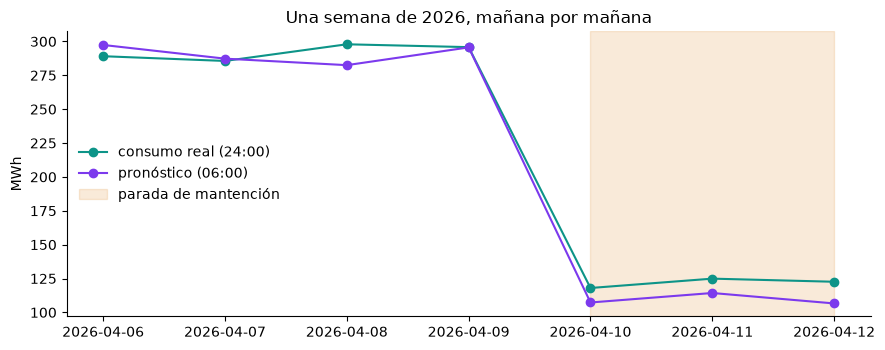

In [14]:
import matplotlib.pyplot as plt

TURQUESA, VIOLETA, AMBAR, ROSA, GRIS = "#0d9488", "#7c3aed", "#d97706", "#e11d48", "#57606a"

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(semana["fecha"], semana["real"], "o-", color=TURQUESA, label="consumo real (24:00)")
ax.plot(semana["fecha"], semana["pronostico"], "o-", color=VIOLETA, label="pronóstico (06:00)")
ax.axvspan(pd.Timestamp("2026-04-10"), pd.Timestamp("2026-04-12"), color=AMBAR, alpha=0.15, label="parada de mantención")
ax.set_ylabel("MWh")
ax.set_title("Una semana de 2026, mañana por mañana")
ax.legend(frameon=False, loc="center left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

El servicio entrega el pronóstico de cada día con lo que había a las 06:00, y el plan de producción, que se conoce de antemano, le permite ver la parada: los tres últimos días el consumo cae a unos 120 MWh y el pronóstico cae con él, aunque queda entre 10 y 16 MWh por debajo del consumo real.

## 7. En Azure

En Azure Machine Learning, la sección 6 tiene dos formas, según cuándo se necesita el pronóstico. La planta lo necesita una vez al día, a las 06:00, lo que apunta a un *batch endpoint*. Para un uso que pide respuesta al momento, un *online endpoint*. Las dos comparten lo que importa en esta lección: **el script importa la misma `armar_features` con que se entrenó** y valida con el mismo contrato.

El script de scoring de un online endpoint tiene dos funciones: `init()` se ejecuta una vez, cuando arranca el contenedor (normalmente justo después de crear o actualizar el deployment), y carga el artefacto; `run()` se ejecuta en cada solicitud. La variable `AZUREML_MODEL_DIR` apunta a los archivos del modelo registrado, y `model` es la carpeta con que se registró.

```python
# src/scoring/score.py
import json
import logging
import os

import joblib
import pandas as pd

from features import armar_features, validar_solicitud  # la misma función del entrenamiento


def init():
    global artefacto
    ruta = os.path.join(os.getenv("AZUREML_MODEL_DIR"), "model", "artefacto.joblib")
    artefacto = joblib.load(ruta)
    artefacto.set_params(bosque__n_jobs=1)


def run(raw_data):
    solicitud = json.loads(raw_data)
    ultimos_dias = pd.DataFrame(solicitud["ultimos_dias"])
    ultimos_dias["fecha"] = pd.to_datetime(ultimos_dias["fecha"])
    hoy = pd.Timestamp(solicitud["hoy"])
    try:
        validar_solicitud(ultimos_dias, hoy)
    except ValueError as falla:
        logging.warning("solicitud rechazada: %s", falla)
        return {"aceptada": False, "motivo": str(falla)}
    x = armar_features(ultimos_dias).loc[[hoy]]
    logging.info("pronóstico para %s", hoy.date())
    return {"aceptada": True, "fecha": str(hoy.date()), "consumo_mwh": float(artefacto.predict(x)[0])}
```

La respuesta HTTP es 200 también cuando la solicitud se rechaza, así que quien llama tiene que mirar el campo `aceptada` antes de usar el número. Devolver un código 400 exige la clase `AMLResponse`, que Microsoft documenta como vista previa.

En el repositorio, `validar_solicitud` de la sección 5 va en `features.py`, junto a `armar_features`. El archivo se despliega junto al script, en la carpeta de `code_configuration`, y el job de entrenamiento lo importa desde el mismo lugar del repositorio. Hay una sola copia, y las dos puntas la usan.

Para el pronóstico de las 06:00 corresponde el batch endpoint, que es el recurso de Azure ML para inferencia asíncrona. Su deployment lleva `type: model`, un `scoring_script` y un `environment` propio, porque los *curated* no se aceptan en batch. Su script recibe en `run()` un mini-lote, que es una lista de rutas de archivos, y devuelve una fila por archivo:

```python
# src/batch/batch_driver.py
import os
from pathlib import Path

import joblib
import pandas as pd

from features import armar_features, validar_solicitud


def init():
    global artefacto
    artefacto = joblib.load(os.path.join(os.environ["AZUREML_MODEL_DIR"], "model", "artefacto.joblib"))
    artefacto.set_params(bosque__n_jobs=1)


def run(mini_batch):  # una lista de rutas de archivos
    resultados = []
    for ruta in mini_batch:
        ultimos_dias = pd.read_csv(ruta, parse_dates=["fecha"])
        hoy = pd.Timestamp(Path(ruta).stem)  # la fecha pedida va en el nombre: 2026-03-11.csv
        validar_solicitud(ultimos_dias, hoy)
        x = armar_features(ultimos_dias).loc[[hoy]]
        resultados.append({"fecha": hoy.date().isoformat(), "consumo_mwh": float(artefacto.predict(x)[0])})
    return pd.DataFrame(resultados)
```

Un orquestador o un workflow programado lo invoca todas las mañanas, con una carpeta que trae un archivo con los ocho últimos días y la fecha a pronosticar en el nombre. El script toma la fecha del nombre y no del contenido: si por error llega el archivo de ayer, la validación lo rechaza en vez de pronosticar ayer. Como en la lección 2, el comando supone que el grupo de recursos y el workspace ya están fijados con `az configure --defaults`:

```bash
az ml batch-endpoint invoke --name consumo-energia-batch --input entrada/
```

El módulo 4 agrega el resto: el deployment, la hora, los reintentos y qué pasa cuando una solicitud se rechaza a las 06:00 y nadie la está mirando.

## Ejercicios

**Ejercicio 1 (una feature escondida).** Alguien agrega al modelo la feature `media_centrada`: el promedio del consumo de tres días, centrado en el día $t$, con `consumo.rolling(3, center=True).mean()`. Agregarla a `armar_features` parece inocente. Medir el error de 2026 con las features en lote y con las features calculadas a las 06:00, y ver cuál de las comprobaciones de la sección 4 la detecta.

*Pista:* ¿qué filas de $T^{(t)}$ entran en el promedio de $t$?

<details>
<summary>Solución</summary>

```python
def armar_features_trampa(tabla):
    f = armar_features(tabla)
    consumo = tabla.set_index("fecha")["consumo"].asfreq("D")
    f["media_centrada"] = consumo.rolling(3, center=True).mean()  # y(t-1), y(t) e y(t+1)
    return f


F_t = armar_features_trampa(df).dropna()
y_t = df.set_index("fecha")["consumo"].loc[F_t.index]
modelo_t = nuevo_pipeline().fit(F_t, y_t)
modelo_t.set_params(bosque__n_jobs=1)

lote_t = armar_features_trampa(serie).loc["2026-01-01":"2026-12-30"]  # el 31 de diciembre no tiene vecino posterior
dia_a_dia_t = pd.concat(
    [armar_features_trampa(a_las_06(serie, hoy)).iloc[[-1]] for hoy in lote_t.index]
)
real = real_2026.loc[lote_t.index]

print(f"MAE en lote:        {mean_absolute_error(real, modelo_t.predict(lote_t)):.2f} MWh")
print(f"MAE a las 06:00:    {mean_absolute_error(real, modelo_t.predict(dia_a_dia_t)):.2f} MWh")
try:
    pd.testing.assert_frame_equal(lote_t, dia_a_dia_t, check_freq=False)
except AssertionError as falla:
    print(str(falla).splitlines()[0])
```

El promedio centrado de $t$ usa $y_{t-1}$, $y_t$ e $y_{t+1}$. A las 06:00 faltan los dos últimos, así que la feature es vacía en $T^{(t)}$ y distinta en la tabla completa: la función no es causal, y `assert_frame_equal` informa que la columna `media_centrada` es distinta. El error en lote es de 4,79 MWh, mucho mejor que el 8,49 del modelo honesto, y es falso: la feature contiene el consumo que se quiere pronosticar. A las 06:00, con la feature vacía, el mismo modelo da 23,92 MWh, peor que la línea base. El MAE en lote no detecta el problema, y la prueba de la sección 4 sí. Lo mismo vale para `shift(-1)` y para cualquier feature que mire hacia adelante.

</details>

**Ejercicio 2 (`get_dummies` no es causal).** Demostrar que la transformación $\varphi$ que codifica el día de la semana con `pd.get_dummies` sobre la columna de la tabla no es causal en el sentido de la Definición 4.3, y comprobarlo con tres días.

*Pista:* ¿de qué depende el número de columnas que devuelve `get_dummies`?

<details>
<summary>Solución</summary>

Sea $T$ una tabla con dos días consecutivos, un miércoles y un jueves, y sea $t$ el miércoles. $\varphi(T)_t$ tiene dos componentes, una por cada día de la semana que aparece en $T$. $T^{(t)}$ solo contiene el miércoles, así que $\varphi(T^{(t)})_t$ tiene una componente. Los dos vectores tienen distinta dimensión, luego $\varphi(T)_t \neq \varphi(T^{(t)})_t$ y $\varphi$ no es causal. $\square$

En general, las columnas dependen del conjunto de categorías que aparece en la tabla, y ese conjunto depende de días posteriores a $t$. Por eso `get_dummies` funciona en el entrenamiento, cuya tabla tiene los siete días, y falla en el servicio, cuya tabla tiene uno. El `OneHotEncoder` con categorías fijas no lo sufre: su salida depende de una constante del código y no de la tabla.

```python
t = armar_features(serie[serie["fecha"] <= "2026-01-02"]).tail(3)  # 31 de dic., 1 y 2 de enero
print(pd.get_dummies(t["dia_semana"], dtype=int))
print(pd.get_dummies(t["dia_semana"].iloc[[0]], dtype=int))
```

Con los tres días salen tres columnas, y con el primero solo una. Con tablas de ocho días el defecto no se notaría, porque ocho días seguidos contienen los siete días de la semana, y por eso es un defecto que se descubre tarde.

</details>

**Ejercicio 3 (el pronóstico de temperatura llega tarde).** Un día el pronóstico de temperatura no está a las 06:00 y la solicitud llega con `NaN`. Medir qué le pasa al error de 2026 si el servicio no valida y ese dato estuviera vacío todos los días, y qué error tendría un modelo entrenado sin la temperatura. Decidir cómo debe responder el servicio.

*Pista:* hay tres respuestas posibles: no pronosticar, usar el pronóstico de ayer o usar un modelo sin temperatura.

<details>
<summary>Solución</summary>

```python
X_sin_temperatura = completas.drop(columns="temperatura")
sin_temperatura = nuevo_pipeline().fit(X_sin_temperatura, y)
sin_temperatura.set_params(bosque__n_jobs=1)

print(f"Con la temperatura:           {mae_2026:.2f} MWh")
print(f"Sin la temperatura:           {mean_absolute_error(real_2026, sin_temperatura.predict(lote.drop(columns='temperatura'))):.2f} MWh")
print(f"Pronóstico vacío sin validar: {mean_absolute_error(real_2026, artefacto.predict(lote.assign(temperatura=np.nan))):.2f} MWh")
print(f"Línea base:                   {mae_base:.2f} MWh")
```

El contrato de la sección 5 rechaza la solicitud con «falta temperatura_pronostico de hoy», y es lo correcto: sin validar, el bosque contesta con la columna vacía y el error de 2026 sube de 8,49 a 9,03 MWh, un cambio que ninguna alarma notaría. Pero rechazar deja a operación sin pronóstico a las 06:00, y la decisión no espera. En esta planta hay una salida mejor: un modelo entrenado sin la temperatura da 8,19 MWh en 2026, no peor que el 8,49, porque el consumo de ayer ya trae casi todo el efecto del clima (el ejercicio 2 de la lección 1 vio algo parecido). El servicio puede entonces responder con ese modelo y marcar la respuesta como `degradado: true`, para que se cuente en el monitoreo (módulo 6). Lo que no debe hacer es pronosticar en silencio con el dato vacío. El pronóstico de ayer como reemplazo es la peor opción: es un dato con otro significado, el mismo error del caso 1.

</details>

**Ejercicio 4 (una unidad cambiada).** Probar el contrato con el consumo de ayer en kWh y en GWh, y con un medidor que se descalibra un 10 %. ¿Cuáles atrapa?

*Pista:* mirar la columna de rangos de la sección 5.

<details>
<summary>Solución</summary>

```python
dia = a_las_06(serie, pd.Timestamp("2026-03-11"), dias=8)

en_kwh = dia.assign(consumo=dia["consumo"] * 1000)
try:
    pronosticar(artefacto, en_kwh, "2026-03-11")
except ValueError as falla:
    print("kWh:", falla)

en_gwh = dia.assign(consumo=dia["consumo"] / 1000)
try:
    pronosticar(artefacto, en_gwh, "2026-03-11")
except ValueError as falla:
    print("GWh:", falla)

con_sesgo = dia.assign(consumo=dia["consumo"] * 1.1)  # el medidor se descalibra un 10 %
print(f"Pronóstico correcto:         {pronosticar(artefacto, dia, '2026-03-11'):.1f} MWh")
print(f"Con el consumo 10 % sobre:   {pronosticar(artefacto, con_sesgo, '2026-03-11'):.1f} MWh")
```

Atrapa los dos cambios de unidad: en kWh el consumo llega mil veces mayor que 600, y en GWh, mil veces menor que 50. El cambio del 10 % pasa el contrato y mueve el pronóstico en 12 MWh, y ningún rango fijo lo atrapa: es un valor plausible pero equivocado. Se detecta comparando la distribución de lo que llega con la de entrenamiento, como hace el monitoreo de *data drift* (módulo 6), y con pruebas estadísticas de los datos (lección 5). El contrato atrapa lo imposible, y el monitoreo, lo que se desvía poco a poco.

</details>

**Siguiente:** la lección 5 convierte estas comprobaciones en pruebas automáticas: `pytest` para los datos, las features y el modelo, de modo que cada cambio las repita antes de llegar a la decisión.